# 6. Машин сургалт (бонус)

`python -m src.models` бүх загварыг сургаж, `reports/metrics.json`-д бичдэг.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)
P, R, F = ROOT / "data" / "processed", ROOT / "reports", ROOT / "figures"
def show(name):
    display(Image(filename=str(F / f"{name}.png"), width=760))

In [2]:
m = json.loads((R / "metrics.json").read_text(encoding="utf-8"))
print("Тоглогчийн хэв маяг (K-Means): бүлэг", m["kmeans"]["k"], "· ялгарал", round(m["kmeans"]["silhouette"], 3), "· дахин тооцоход давхцал", round(m["kmeans"]["bootstrap_ari"], 3))

Тоглогчийн хэв маяг (K-Means): бүлэг 3 · ялгарал 0.209 · дахин тооцоход давхцал 0.785


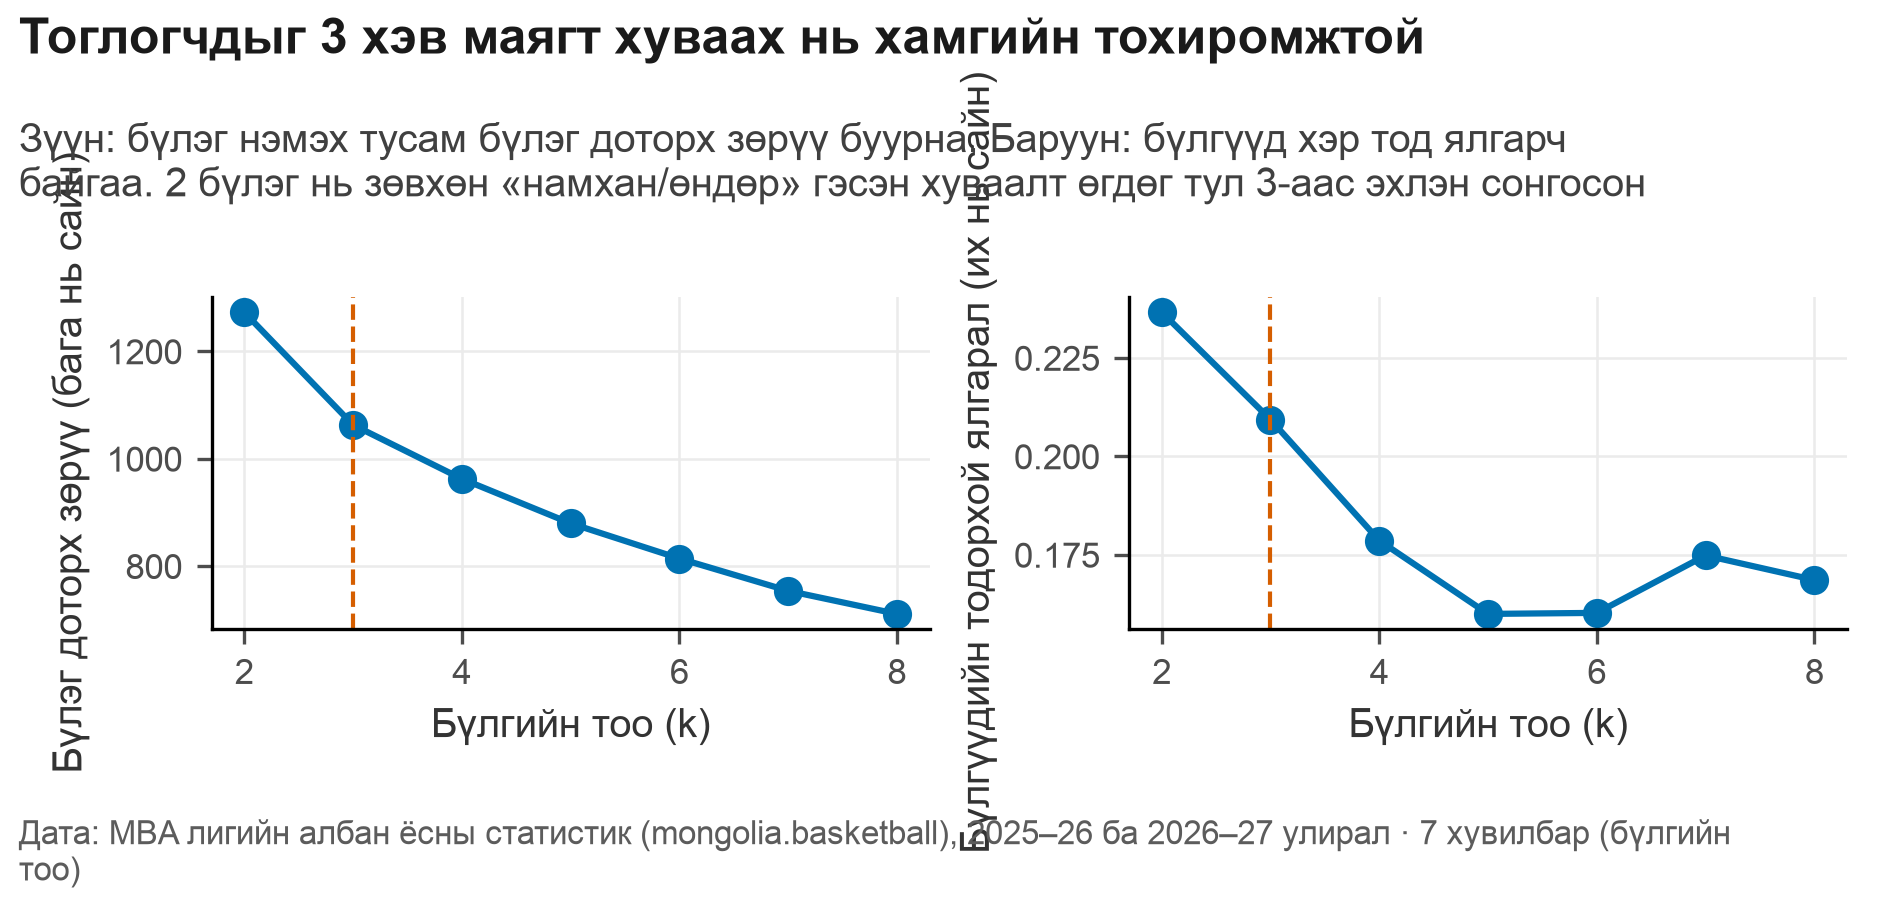

In [3]:
show("F14a_elbow_silhouette")

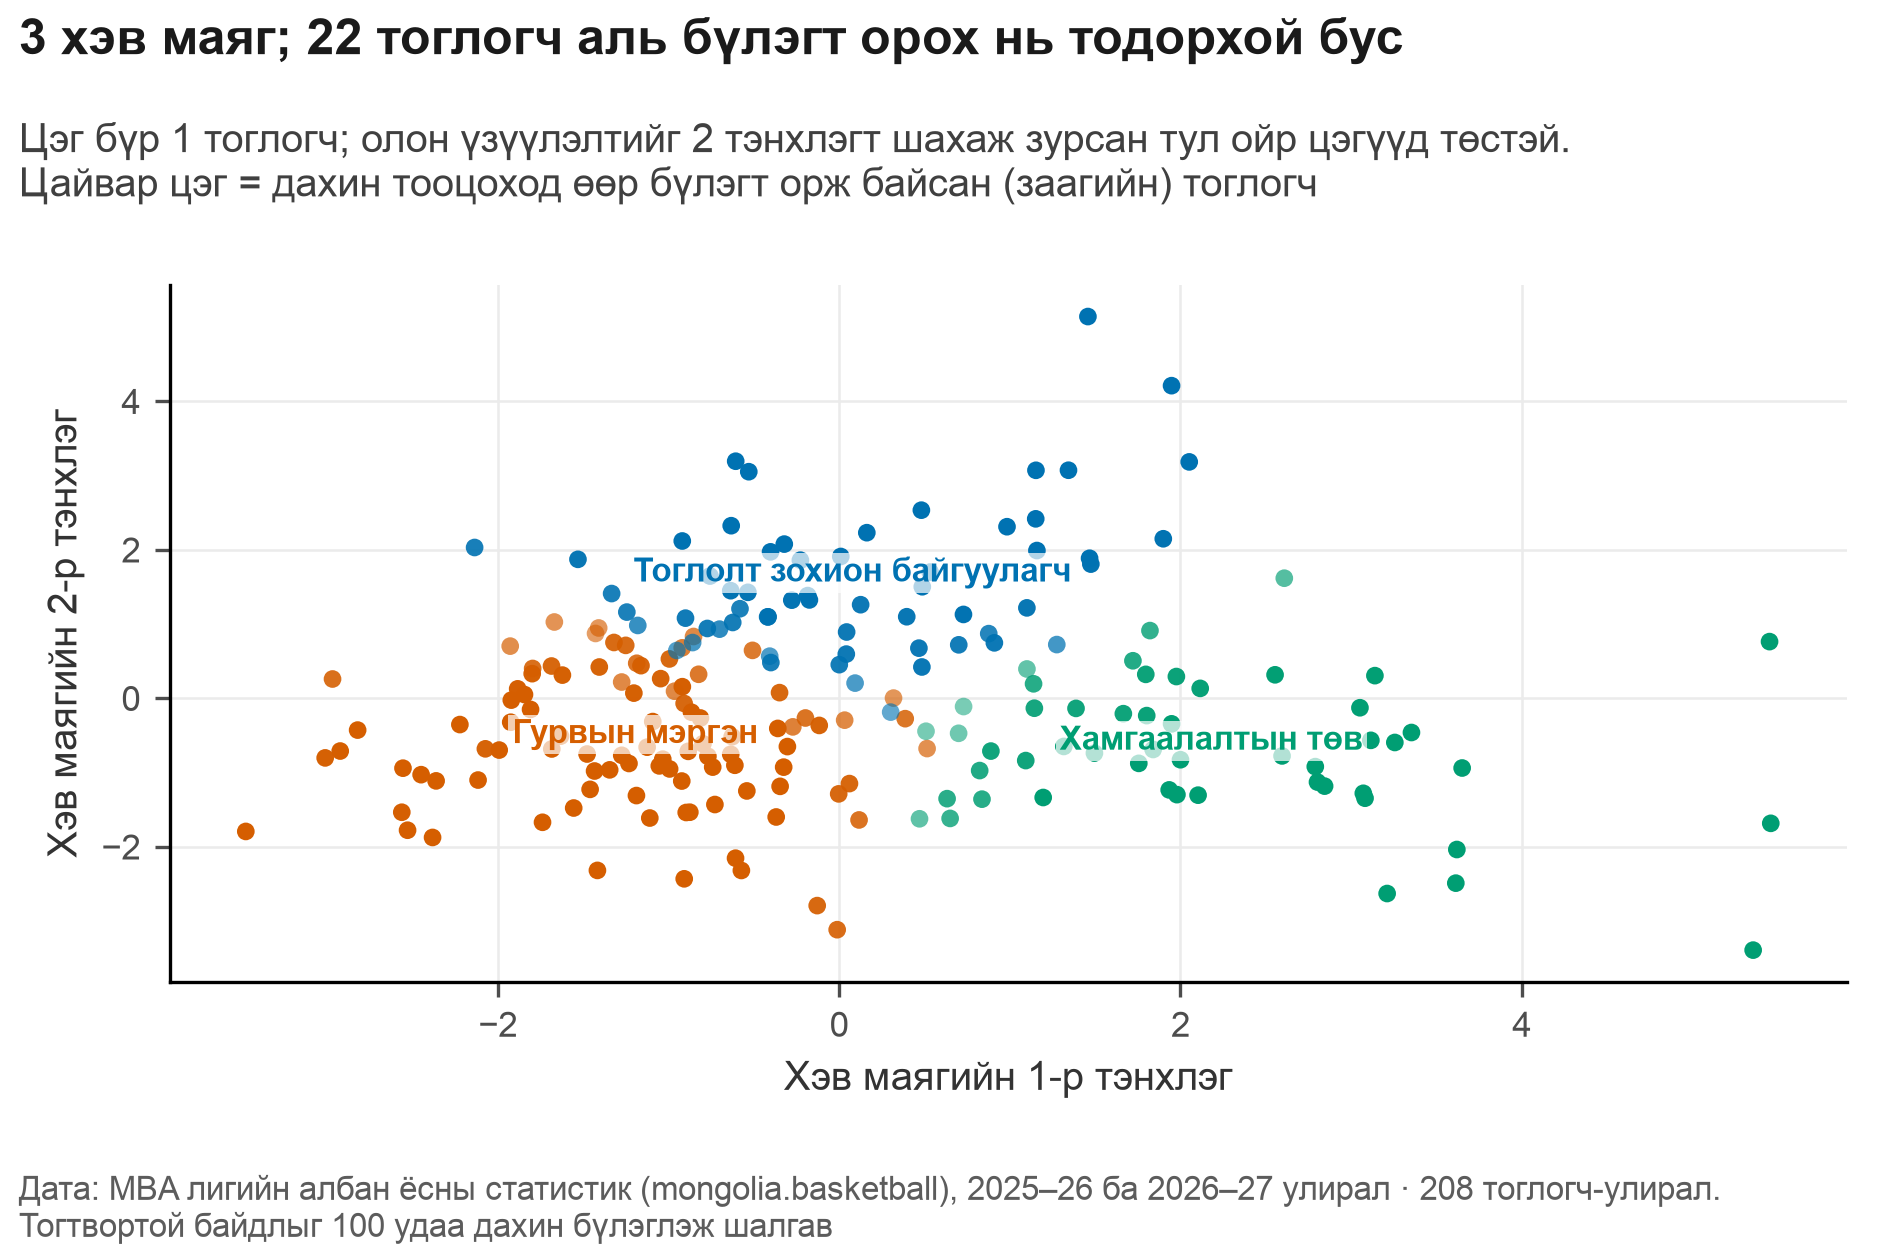

In [4]:
show("F14b_pca_clusters")

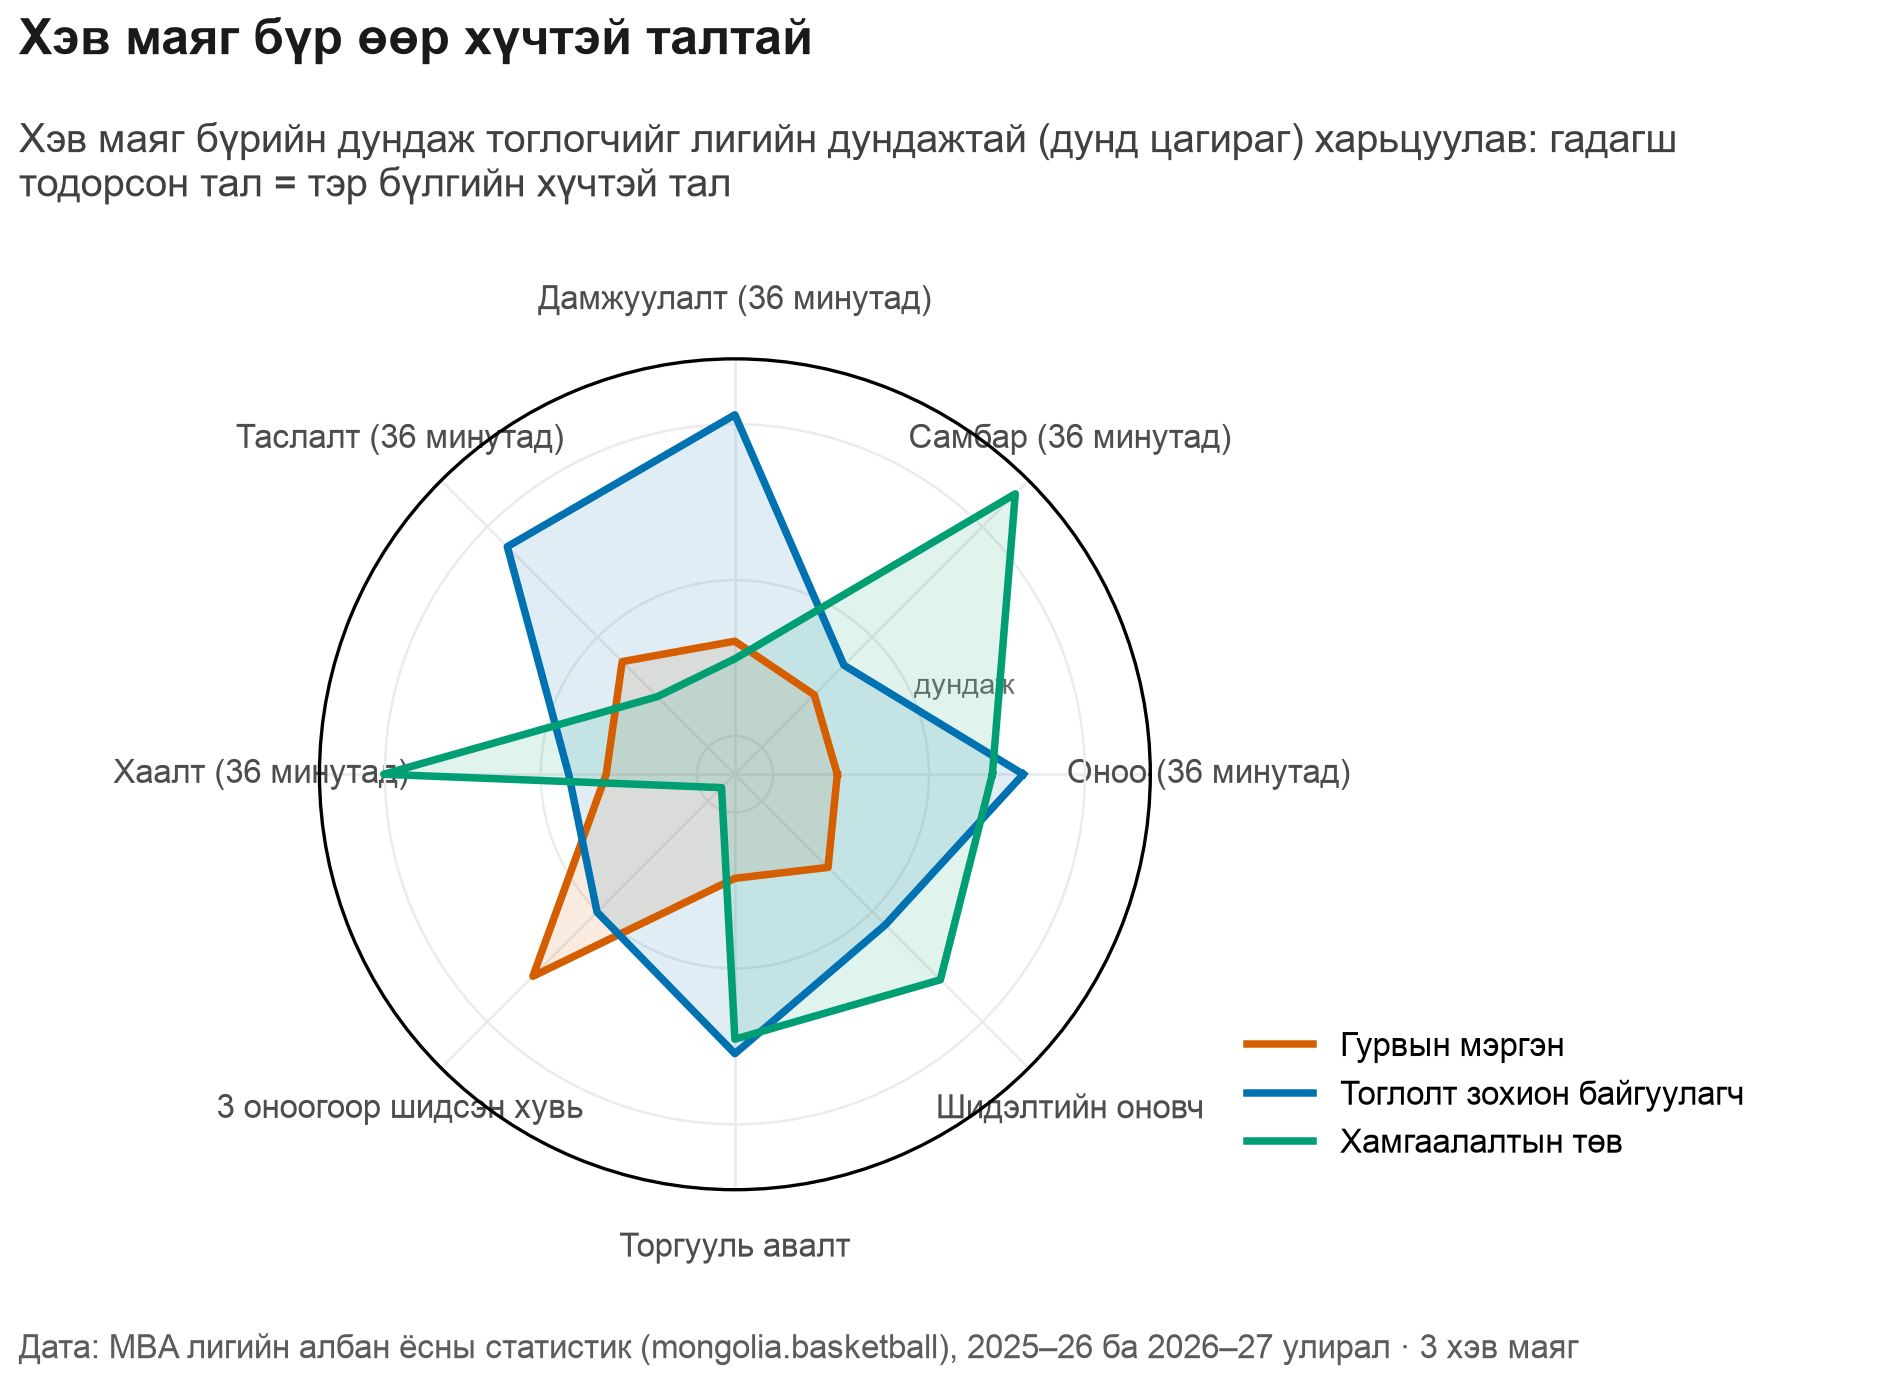

In [5]:
show("F14c_radar")

In [6]:
display(pd.read_csv(R / "cluster_composition.csv")); pd.read_csv(R / "cluster_centroids.csv").round(3)

,cluster_name,n,pct_import,PG,SG,SF,PF,C
0,Гурвын мэргэн,97,6.185567,18,32,21,17,9
1,Тоглолт зохион байгуулагч,60,45.000000,33,12,9,4,2
2,Хамгаалалтын төв,51,54.901961,4,3,5,8,31


,cluster_name,pts36,reb36,ast36,stl36,blk36,tpa_rate,ftr,ts_pct
0,Гурвын мэргэн,10.626,4.725,2.322,1.471,0.291,0.524,0.217,0.502
1,Хамгаалалтын төв,16.072,9.836,2.124,1.231,1.271,0.150,0.374,0.577
2,Тоглолт зохион байгуулагч,17.157,5.479,4.866,2.258,0.456,0.396,0.388,0.540


## Тоглолтын өмнө ялагчийг таамаглах

Загварыг он цагийн дарааллаар өмнөх тоглолтоор сургаж, дараагийнхыг таамаглуулсан (walk-forward).

In [7]:
pd.DataFrame(m["win_cv"]).T.round(3)

,accuracy_mean,accuracy_std,auc_mean,auc_std,brier_mean,brier_std
baseline_elo,0.603,0.059,0.603,0.063,0.397,0.059
baseline_winpct,0.570,0.019,0.597,0.015,0.391,0.021
logreg,0.592,0.091,0.655,0.116,0.233,0.034
rf,0.547,0.081,0.591,0.084,0.255,0.028


In [8]:
pd.DataFrame({k: {kk: f"{vv['est']:.3f} [{vv['lo']:.3f}, {vv['hi']:.3f}]" for kk, vv in v.items()} for k, v in m["win_bootstrap"].items()}).T

,accuracy,auc,brier
baseline_elo,"0.601 [0.530, 0.667]","0.601 [0.531, 0.668]","0.399 [0.333, 0.470]"
baseline_winpct,"0.568 [0.497, 0.634]","0.594 [0.522, 0.666]","0.391 [0.326, 0.454]"
logreg,"0.585 [0.519, 0.656]","0.638 [0.563, 0.716]","0.235 [0.213, 0.258]"
rf,"0.546 [0.481, 0.617]","0.583 [0.503, 0.661]","0.257 [0.234, 0.283]"


In [9]:
pd.read_csv(R / "season_holdout.csv").round(3)

,model,n_train,n_test,accuracy,auc,brier
0,logreg,156,64,0.641,0.659,0.224
1,rf,156,64,0.594,0.604,0.244
2,baseline_elo,156,64,0.641,0.641,0.359
3,baseline_winpct,156,64,0.531,0.584,0.379


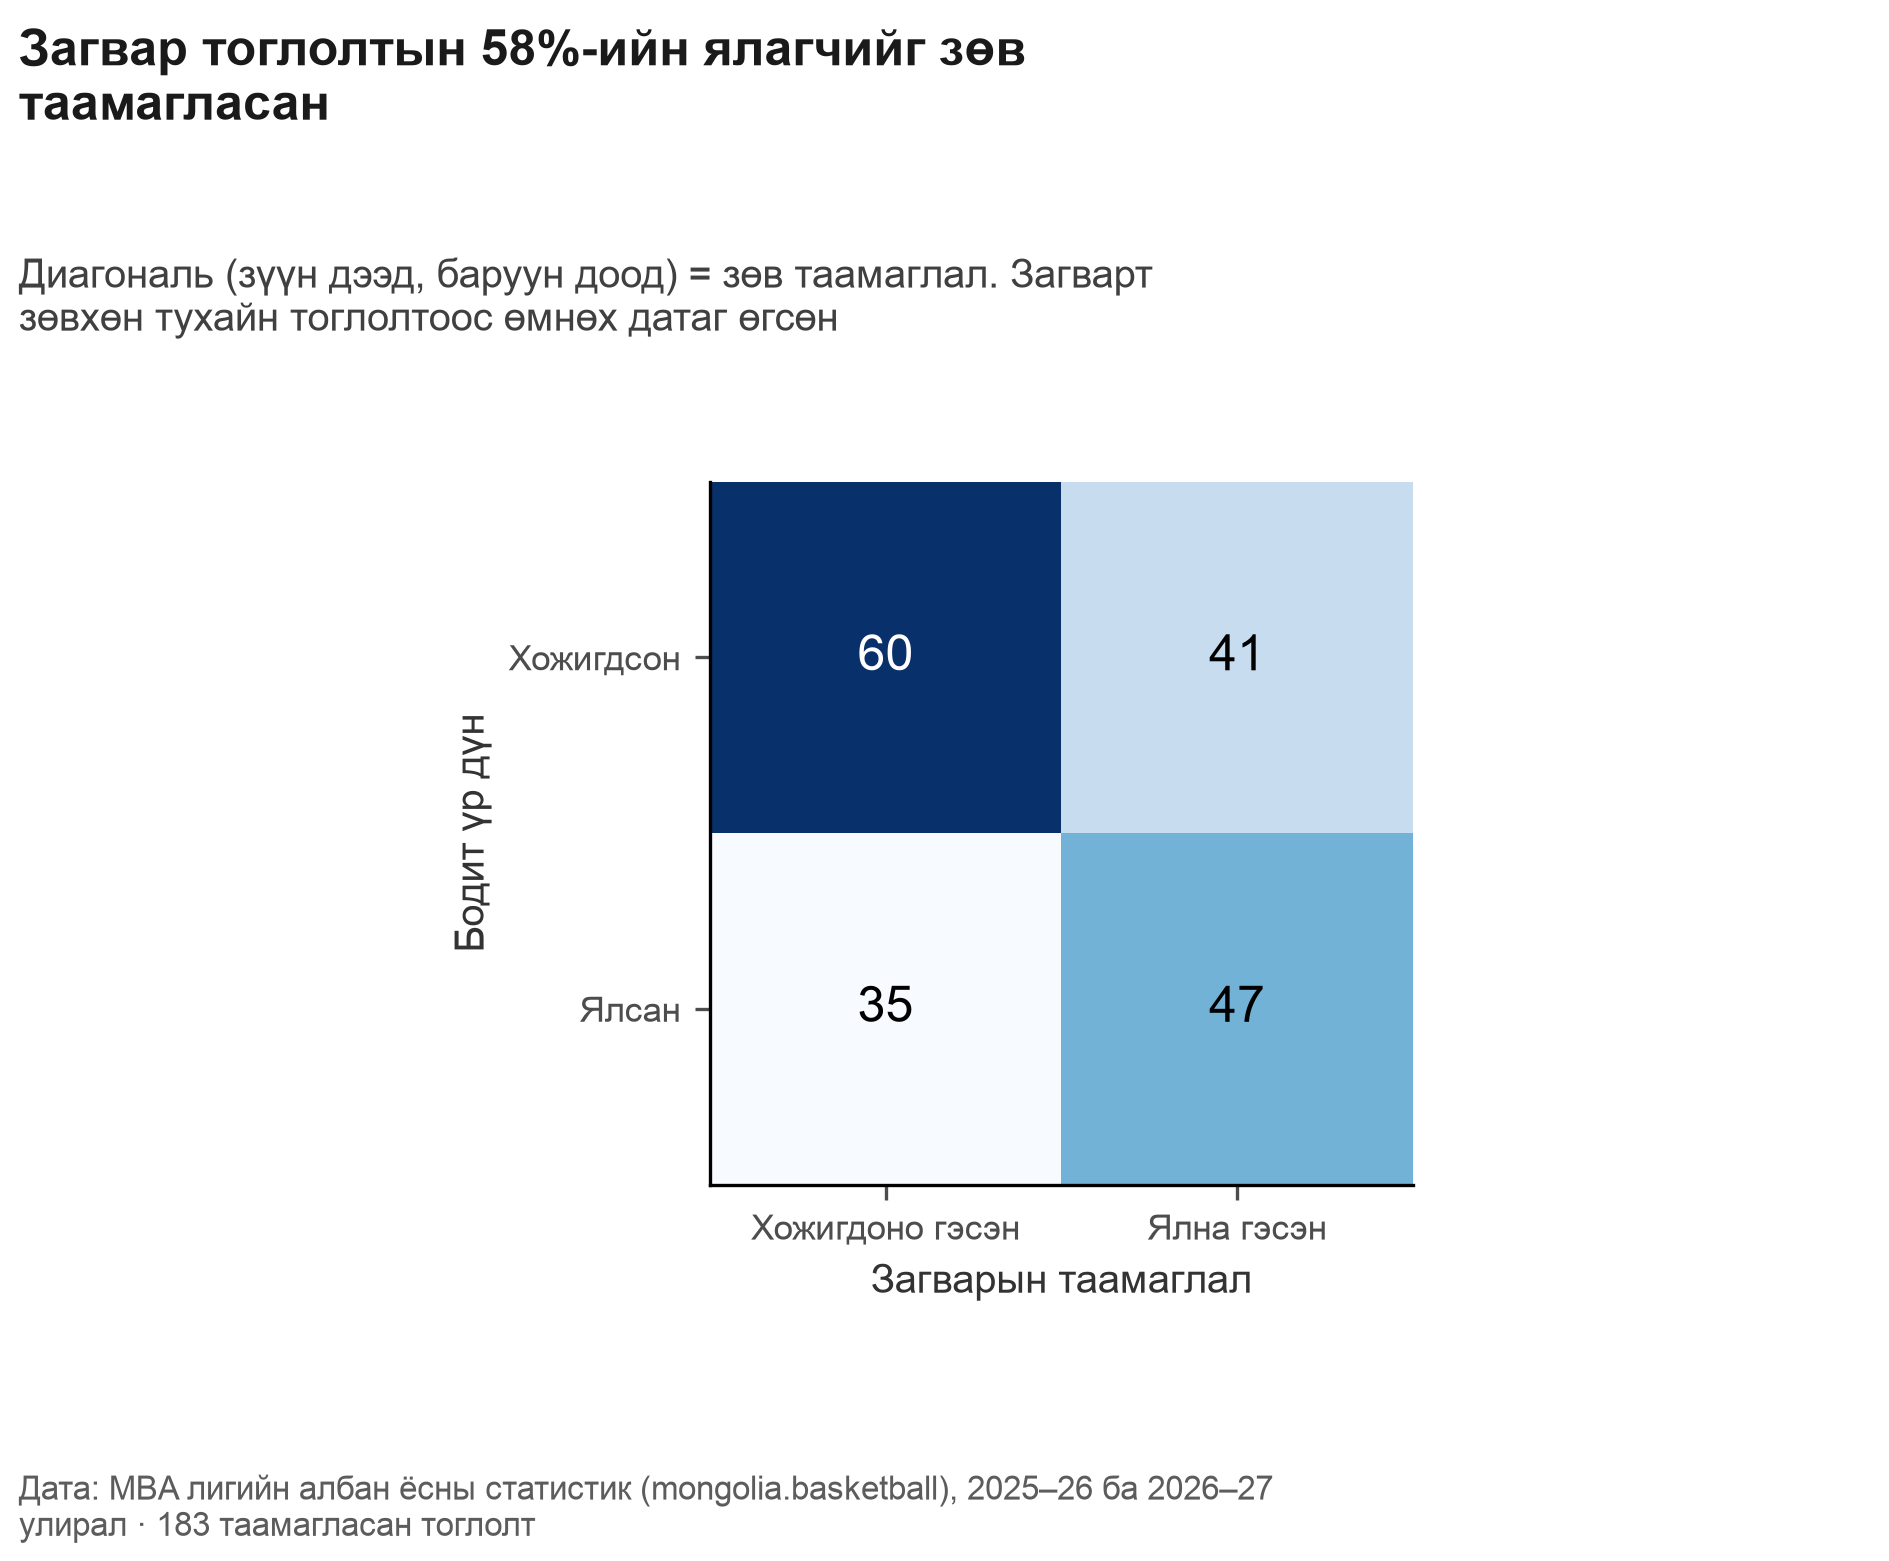

In [10]:
show("F14d_confusion")

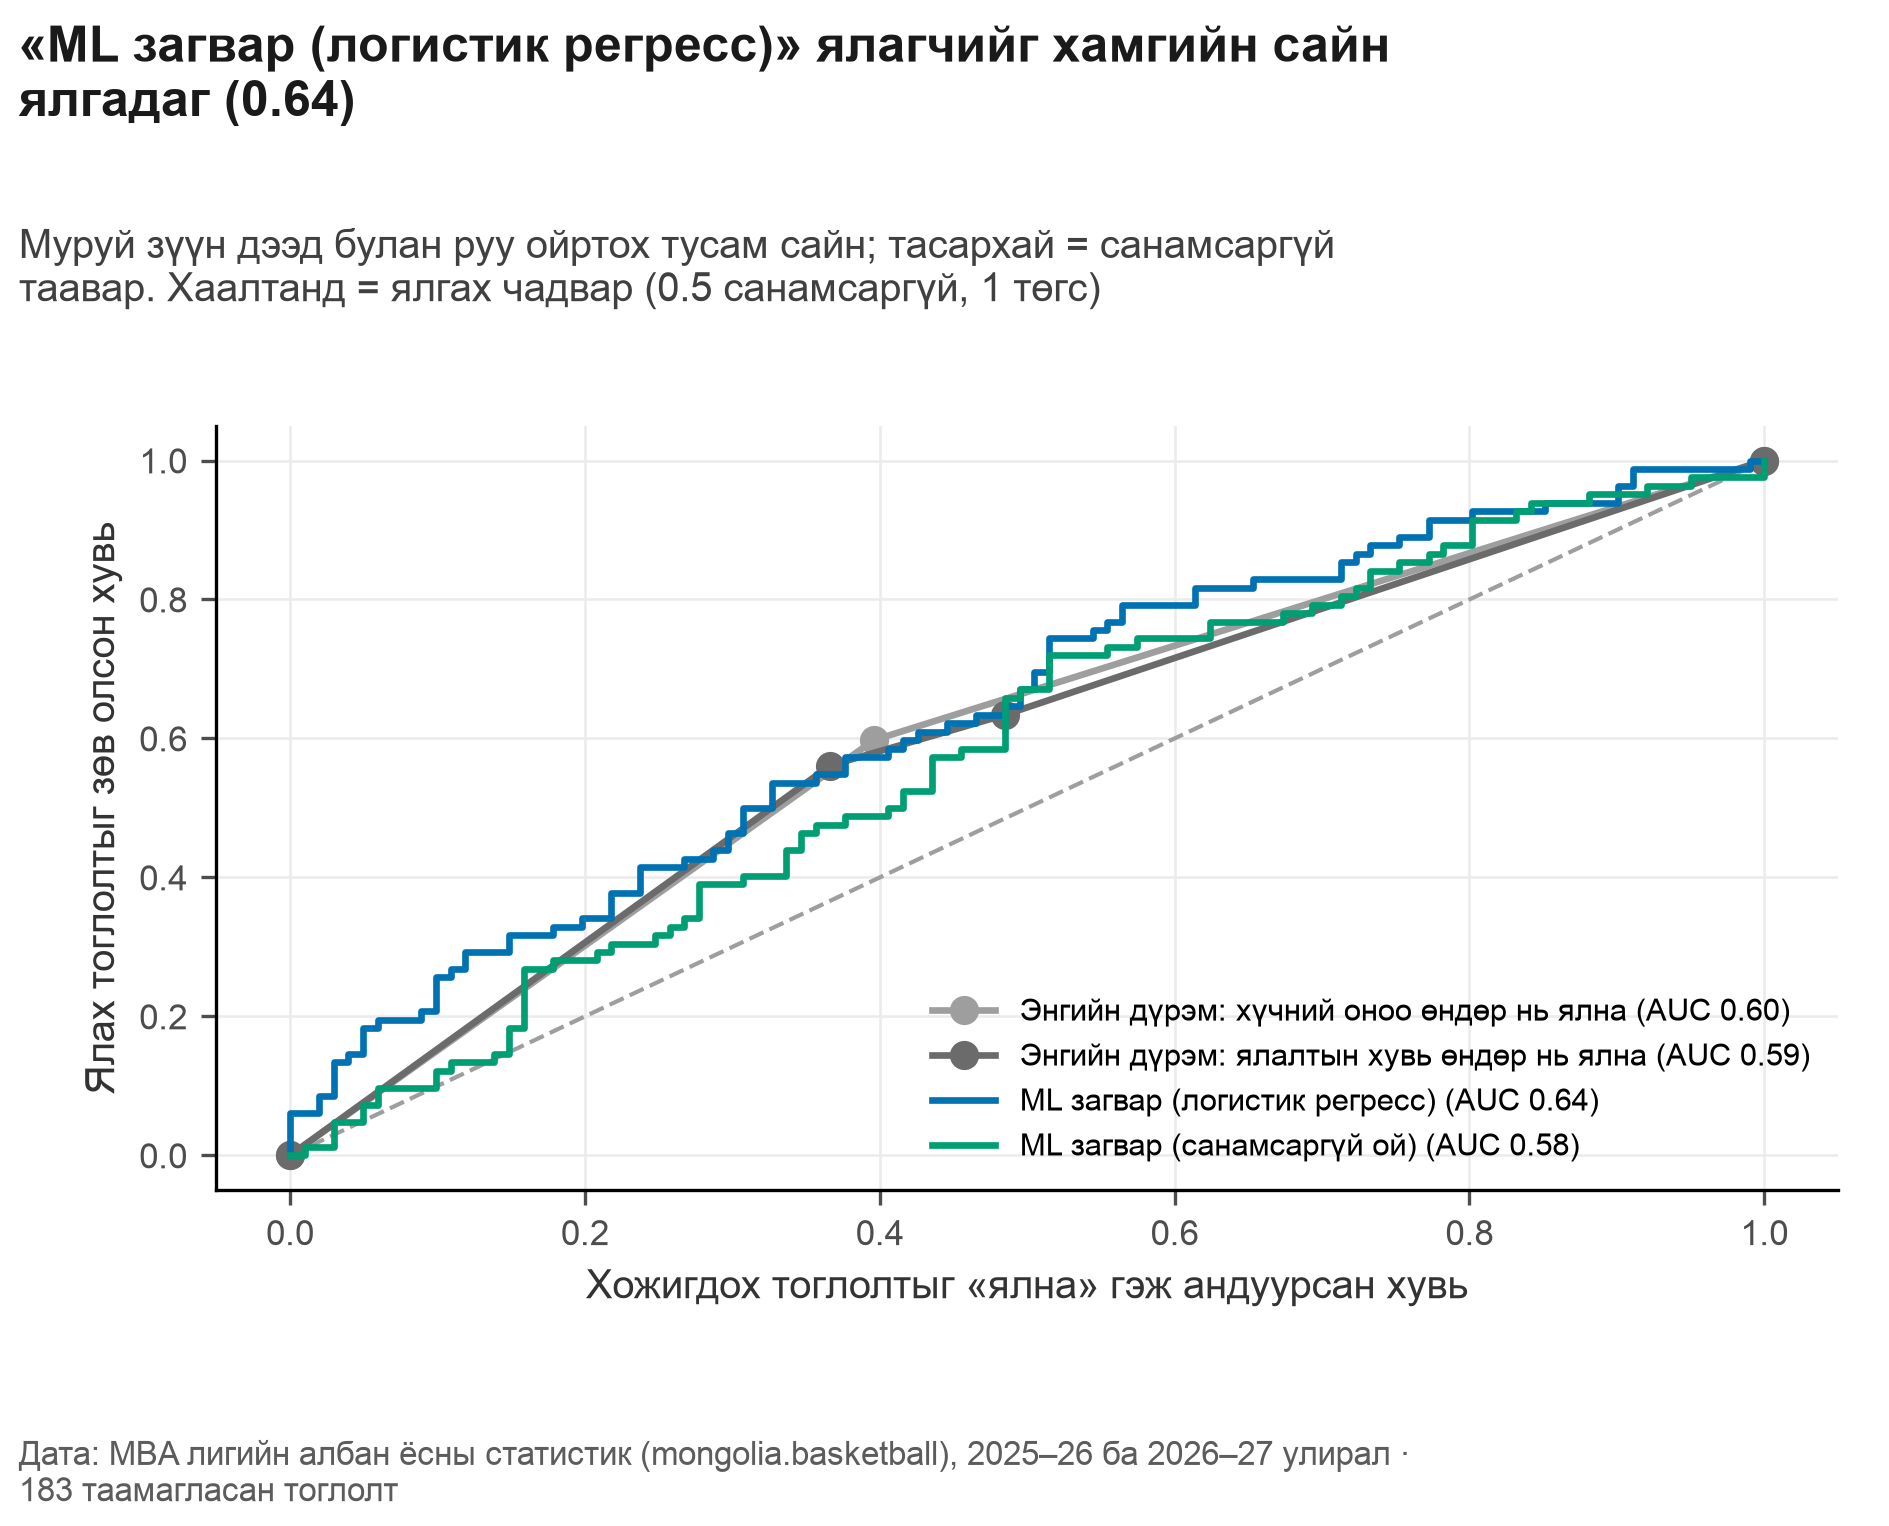

In [11]:
show("F14e_roc")

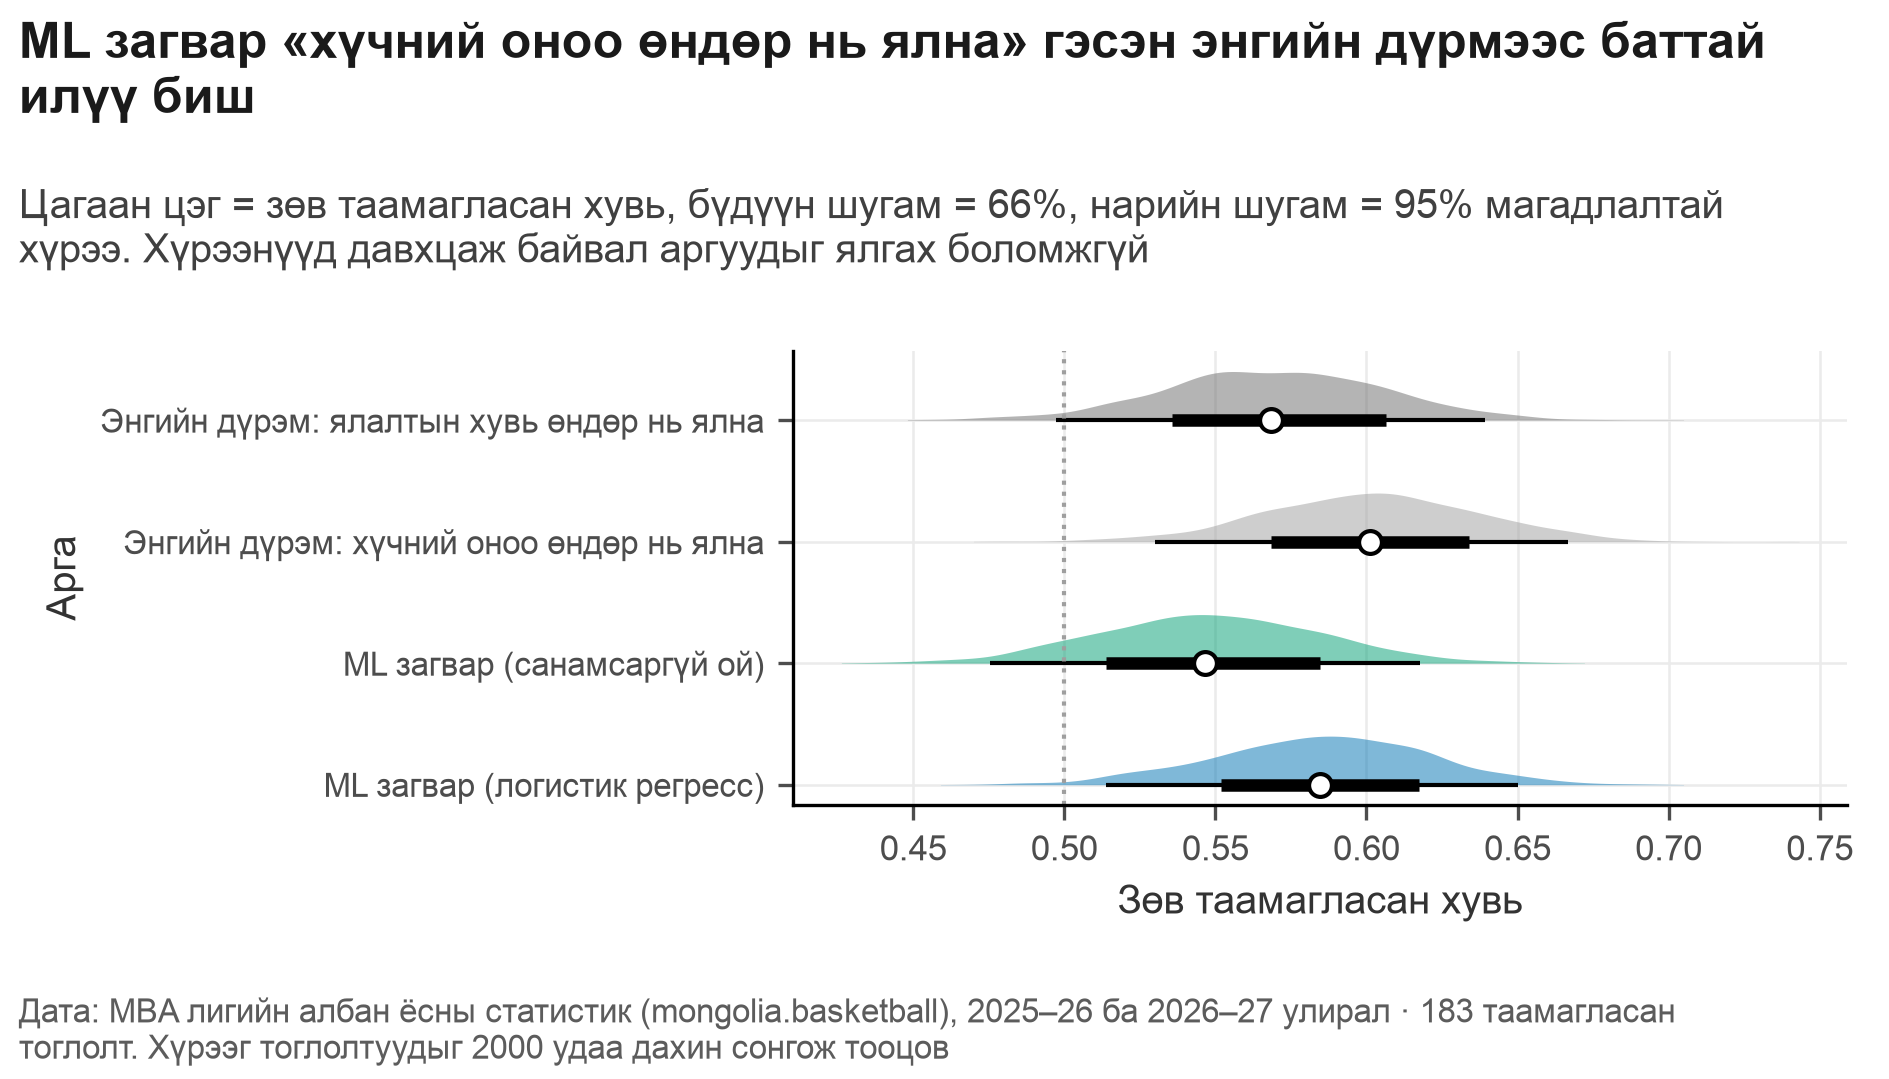

In [12]:
show("U06a_model_accuracy")

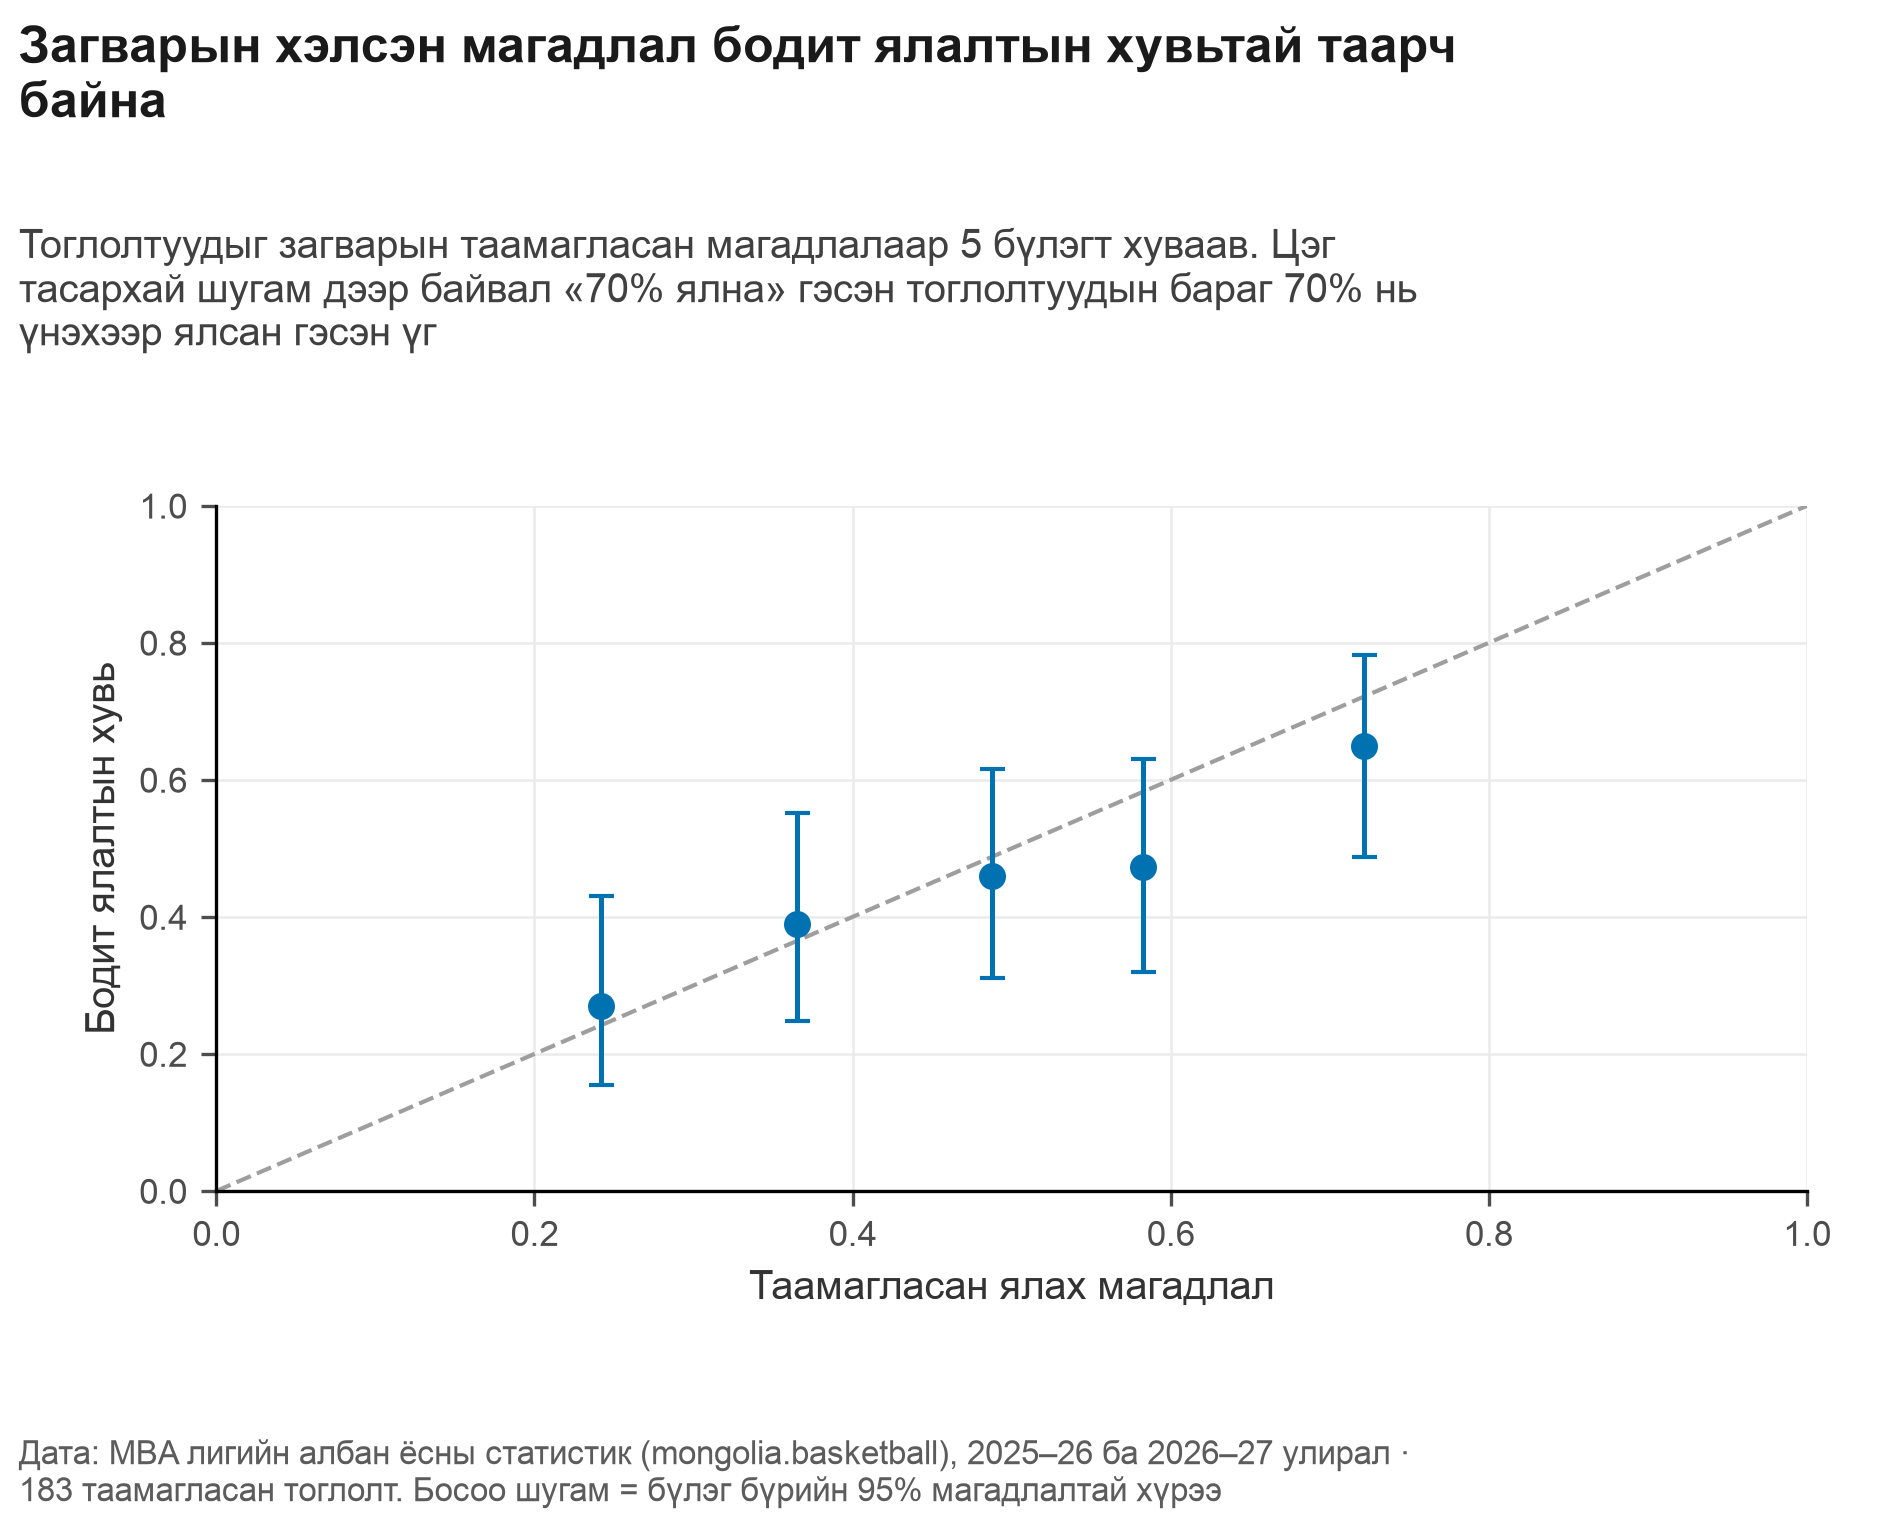

In [13]:
show("U06b_calibration")

**[Ноорог — өөрийн үгээр дахин бичих]** Загвар «хүчний оноо өндөр нь ялна» гэсэн энгийн дүрмийг баттай давж чадаагүйг, яагаад гэдгийг (дата цөөн, багууд тэнцүү) өөрийн үгээр тайлбарлана.

## Тоглолтын дундах ялах магадлал

Тоглолт бүрийг минут тутам зогсоож (онооны зөрүү, үлдсэн хугацаа, тоглолтын өмнөх хүч) гэрийн баг ялах магадлалыг тооцсон. Нэг тоглолтын мөчүүд сургалт, тест хоёрт зэрэг орохгүй.

In [14]:
ip = m["inplay"]
print(f"{ip['n_states']:,} мөч, {ip['n_games']} тоглолт · зөв таамагласан {ip['acc']:.1%} (энгийн дүрэм {ip['acc_leader']:.1%}) · Brier {ip['brier']:.3f}")
pd.read_csv(R / "inplay_minute.csv").iloc[::5].round(3)

10,080 мөч, 252 тоглолт · зөв таамагласан 71.8% (энгийн дүрэм 72.1%) · Brier 0.180


,minute,n,brier,acc_model,lo_model,hi_model,acc_leader,lo_leader,hi_leader
0,0,252,0.250,0.556,0.488,0.611,0.567,0.512,0.627
5,5,252,0.231,0.639,0.579,0.698,0.647,0.587,0.710
10,10,252,0.225,0.655,0.595,0.710,0.639,0.579,0.694
15,15,252,0.214,0.655,0.599,0.710,0.643,0.587,0.698
20,20,252,0.186,0.722,0.671,0.778,0.714,0.663,0.774
25,25,252,0.164,0.762,0.710,0.810,0.774,0.718,0.821
30,30,252,0.133,0.813,0.766,0.861,0.821,0.774,0.869
35,35,252,0.101,0.837,0.786,0.881,0.857,0.813,0.897


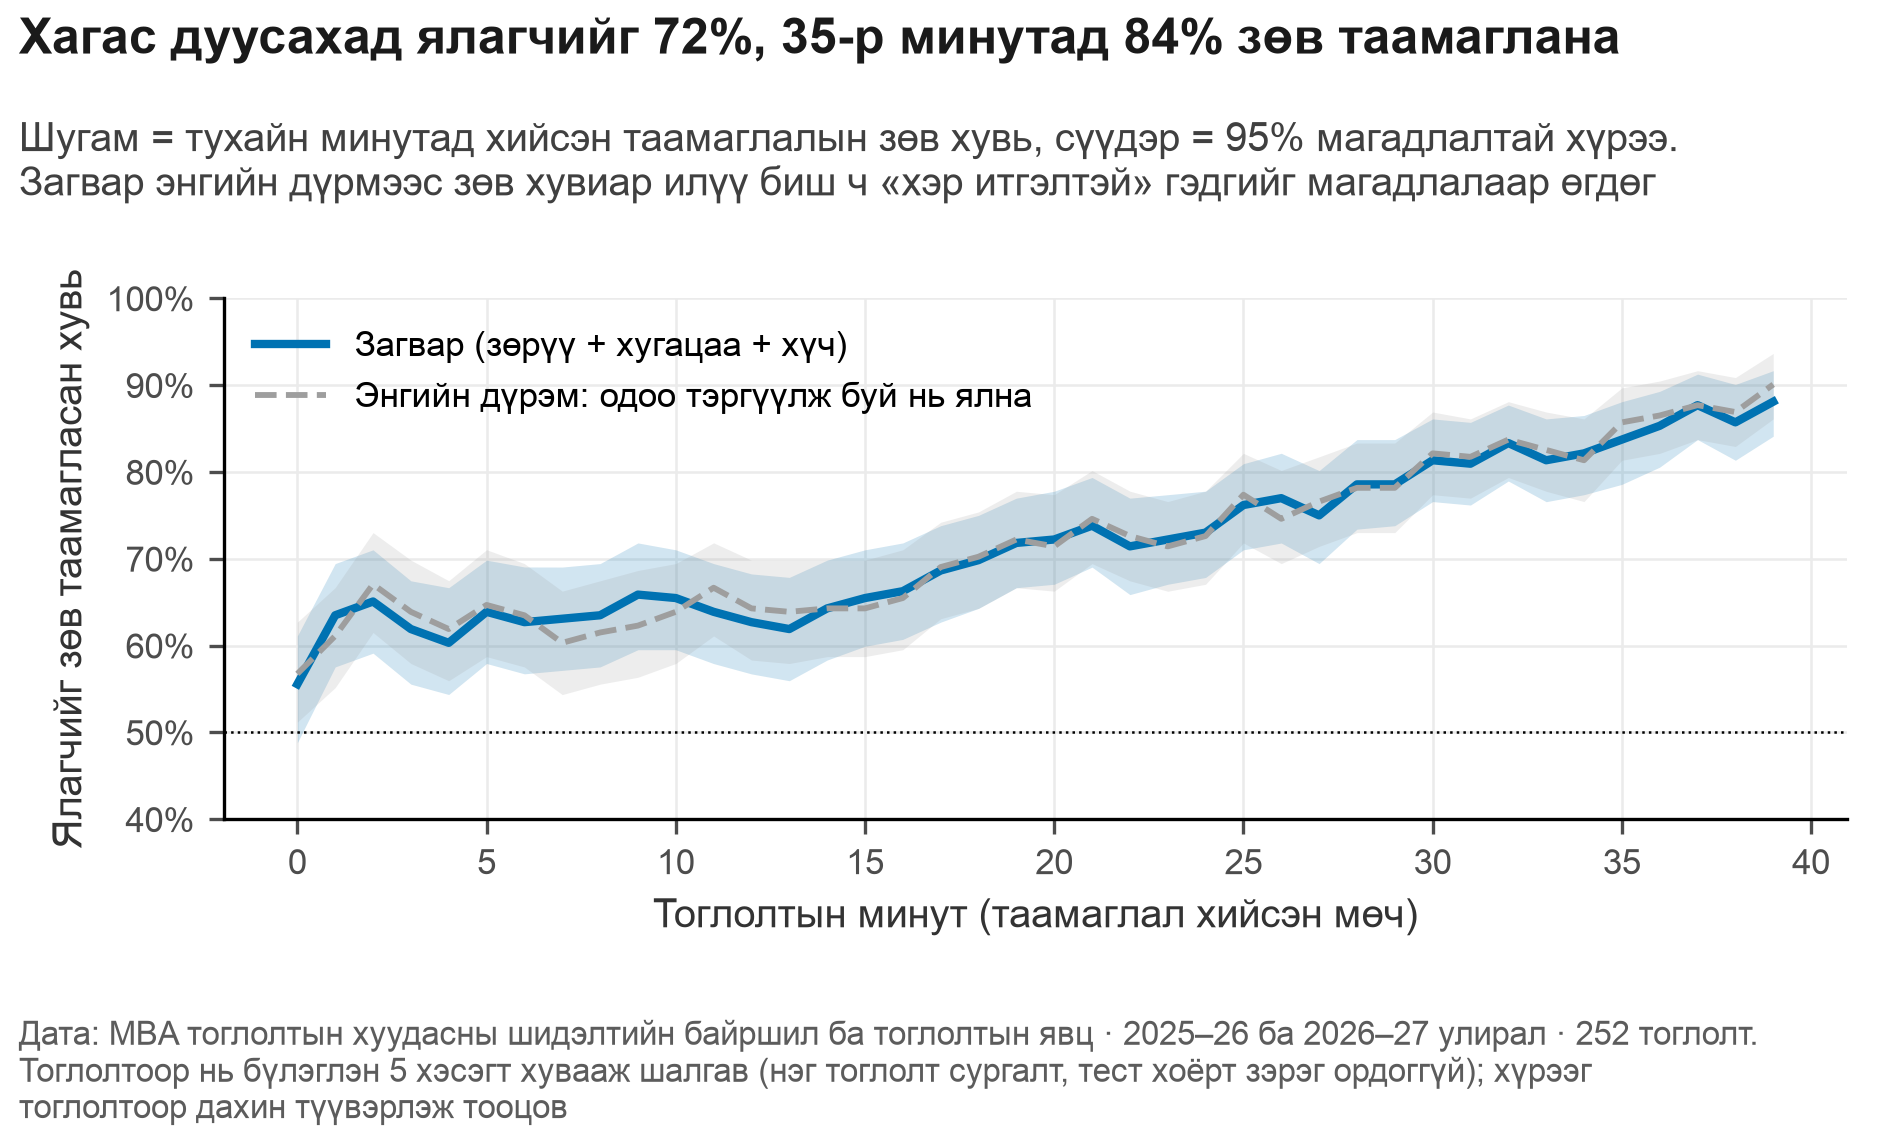

In [15]:
show("U10_inplay_accuracy")

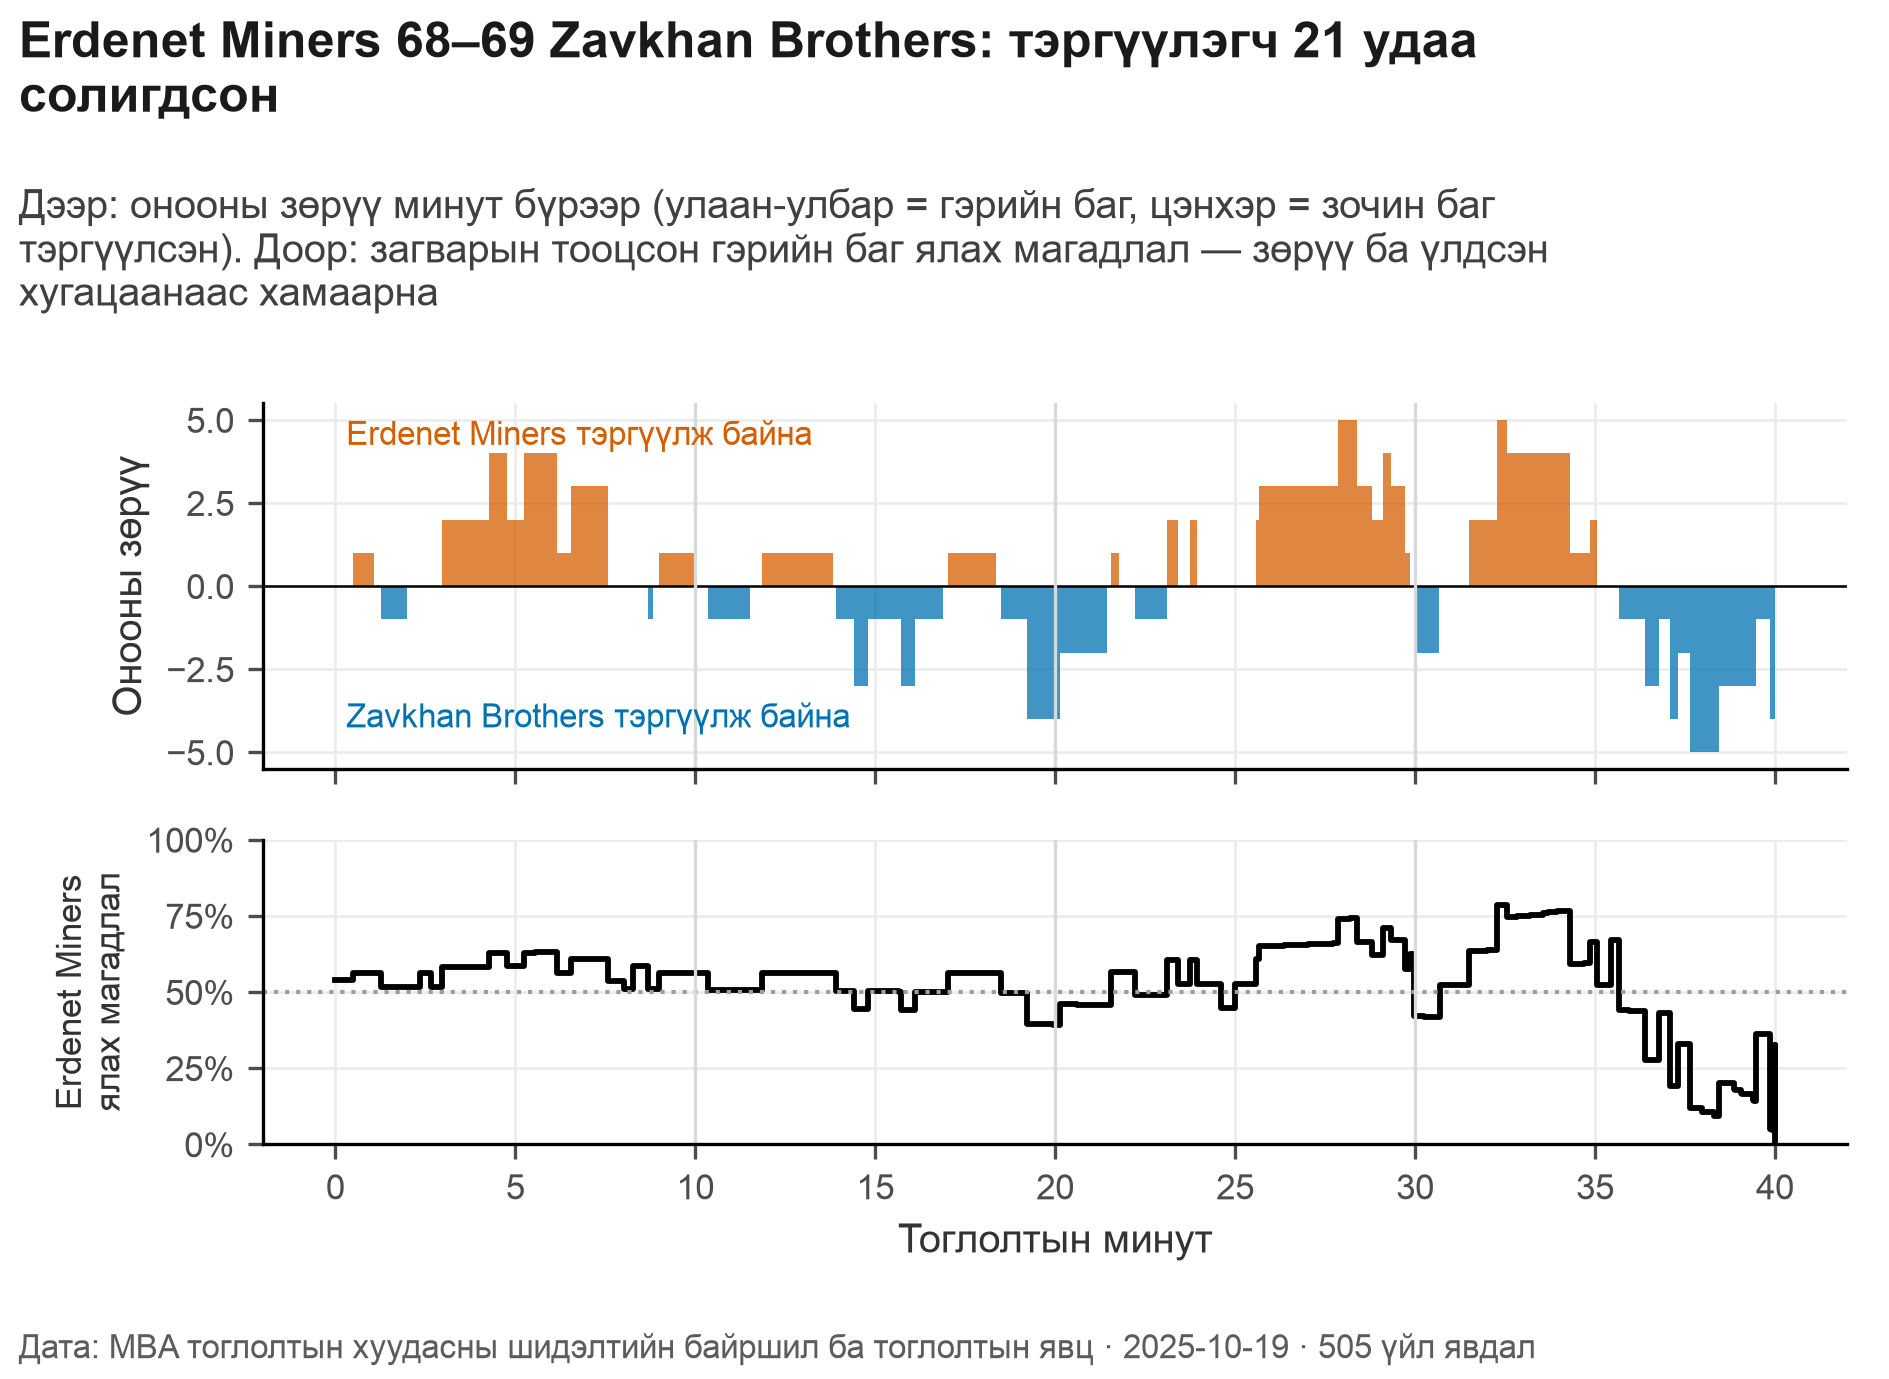

In [16]:
show("F18_game_flow")

## Тайлбар загвар ба Pythagorean

In [17]:
display(pd.read_csv(R / "explanatory.csv").round(3)); m["pythagorean"]

,feature,coef,lo,hi,perm_importance,perm_lo,perm_hi
0,efg,3.833,3.506,4.227,0.399,0.329,0.464
1,tov_pct,-1.914,-2.281,-1.589,0.093,0.064,0.116
2,orb_pct,1.574,1.249,1.953,0.073,0.056,0.095
3,ftr,1.010,0.679,1.431,0.034,0.020,0.047


{'exponent': 10.809989984867057,
 'exponent_ci': {'est': 10.809989984867057,
  'lo': 9.533777223711319,
  'hi': 12.10317673576825},
 'r2': 0.8861585148328418,
 'r2_ci': {'est': 0.8861585148328418,
  'lo': 0.7922641715417368,
  'hi': 0.9421569167640023},
 'mae': 0.05082439063695716,
 'mae_13_91': 0.06012112740153742,
 'n': 33}

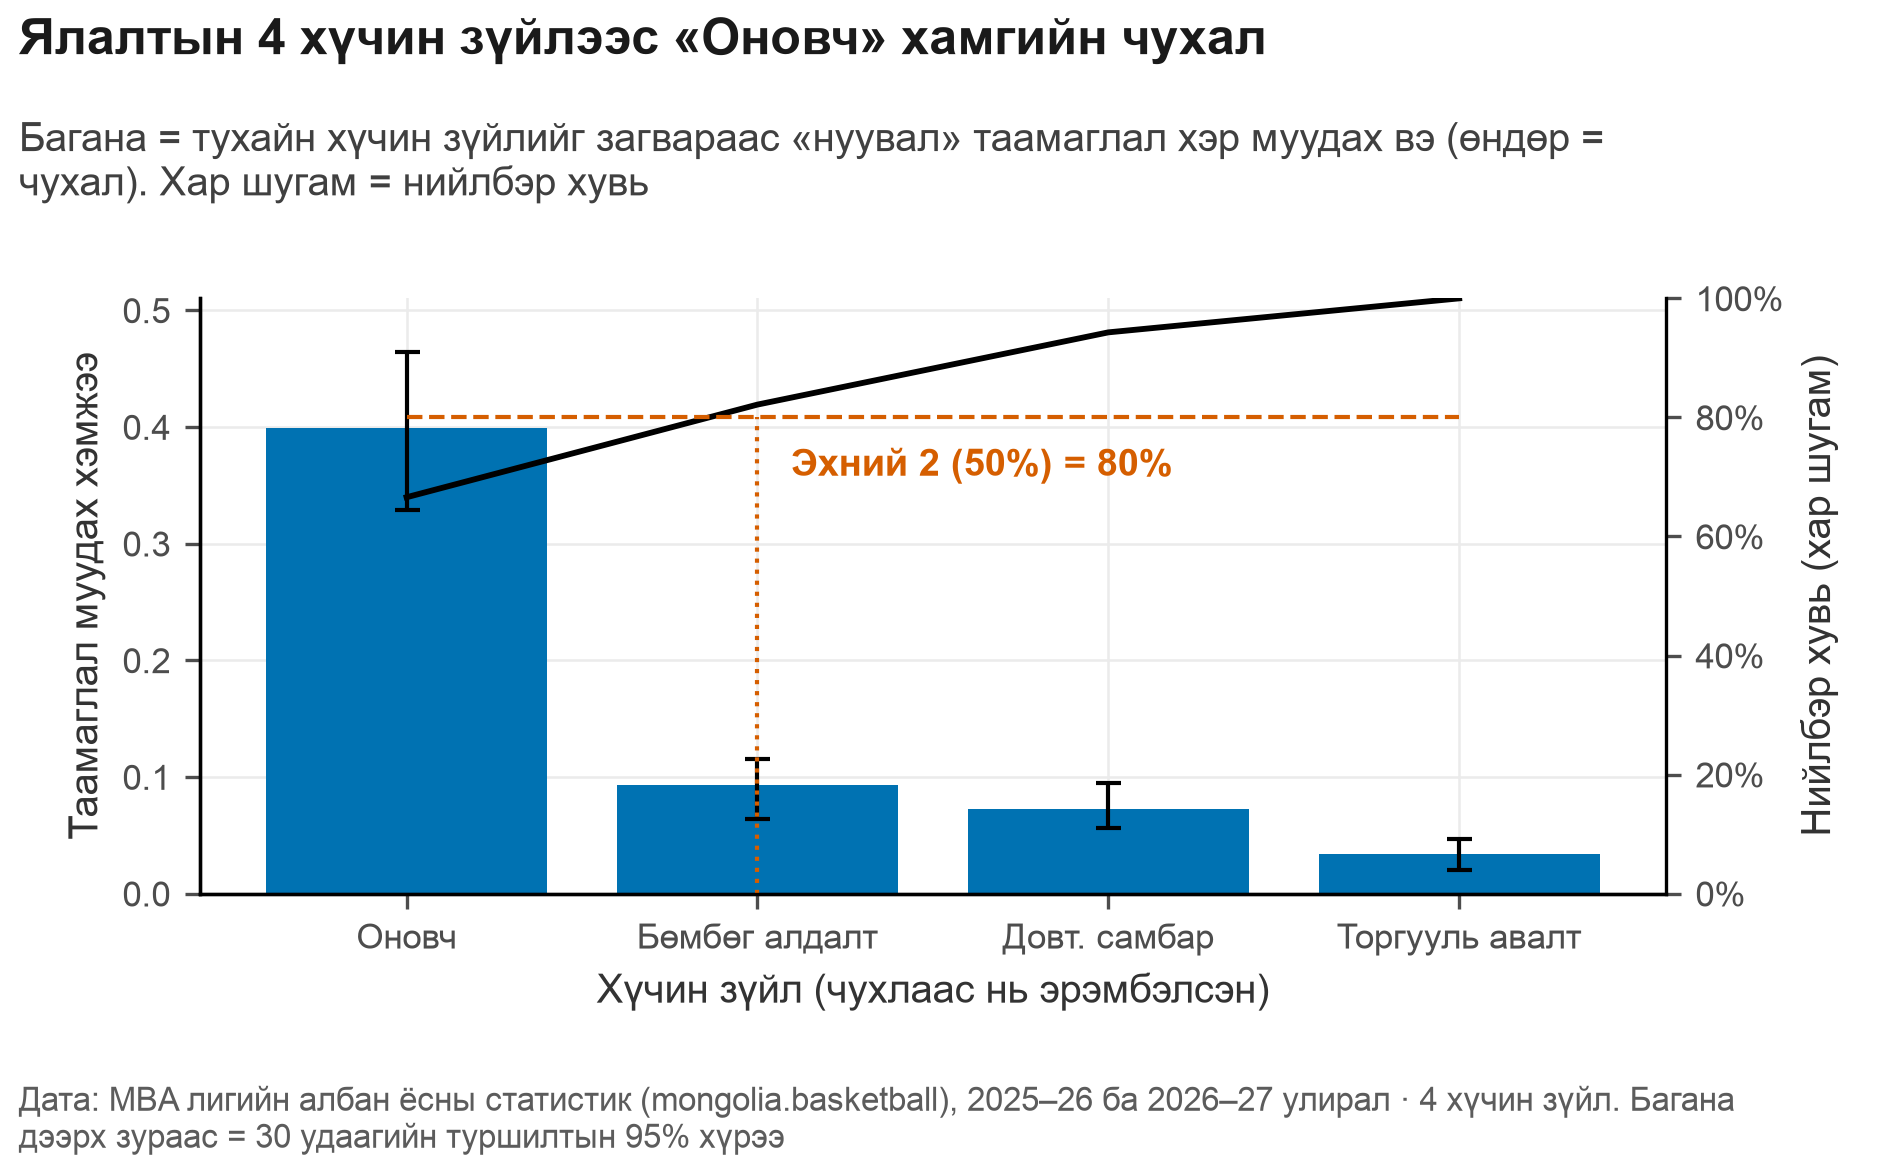

In [18]:
show("P3_importance_pareto")

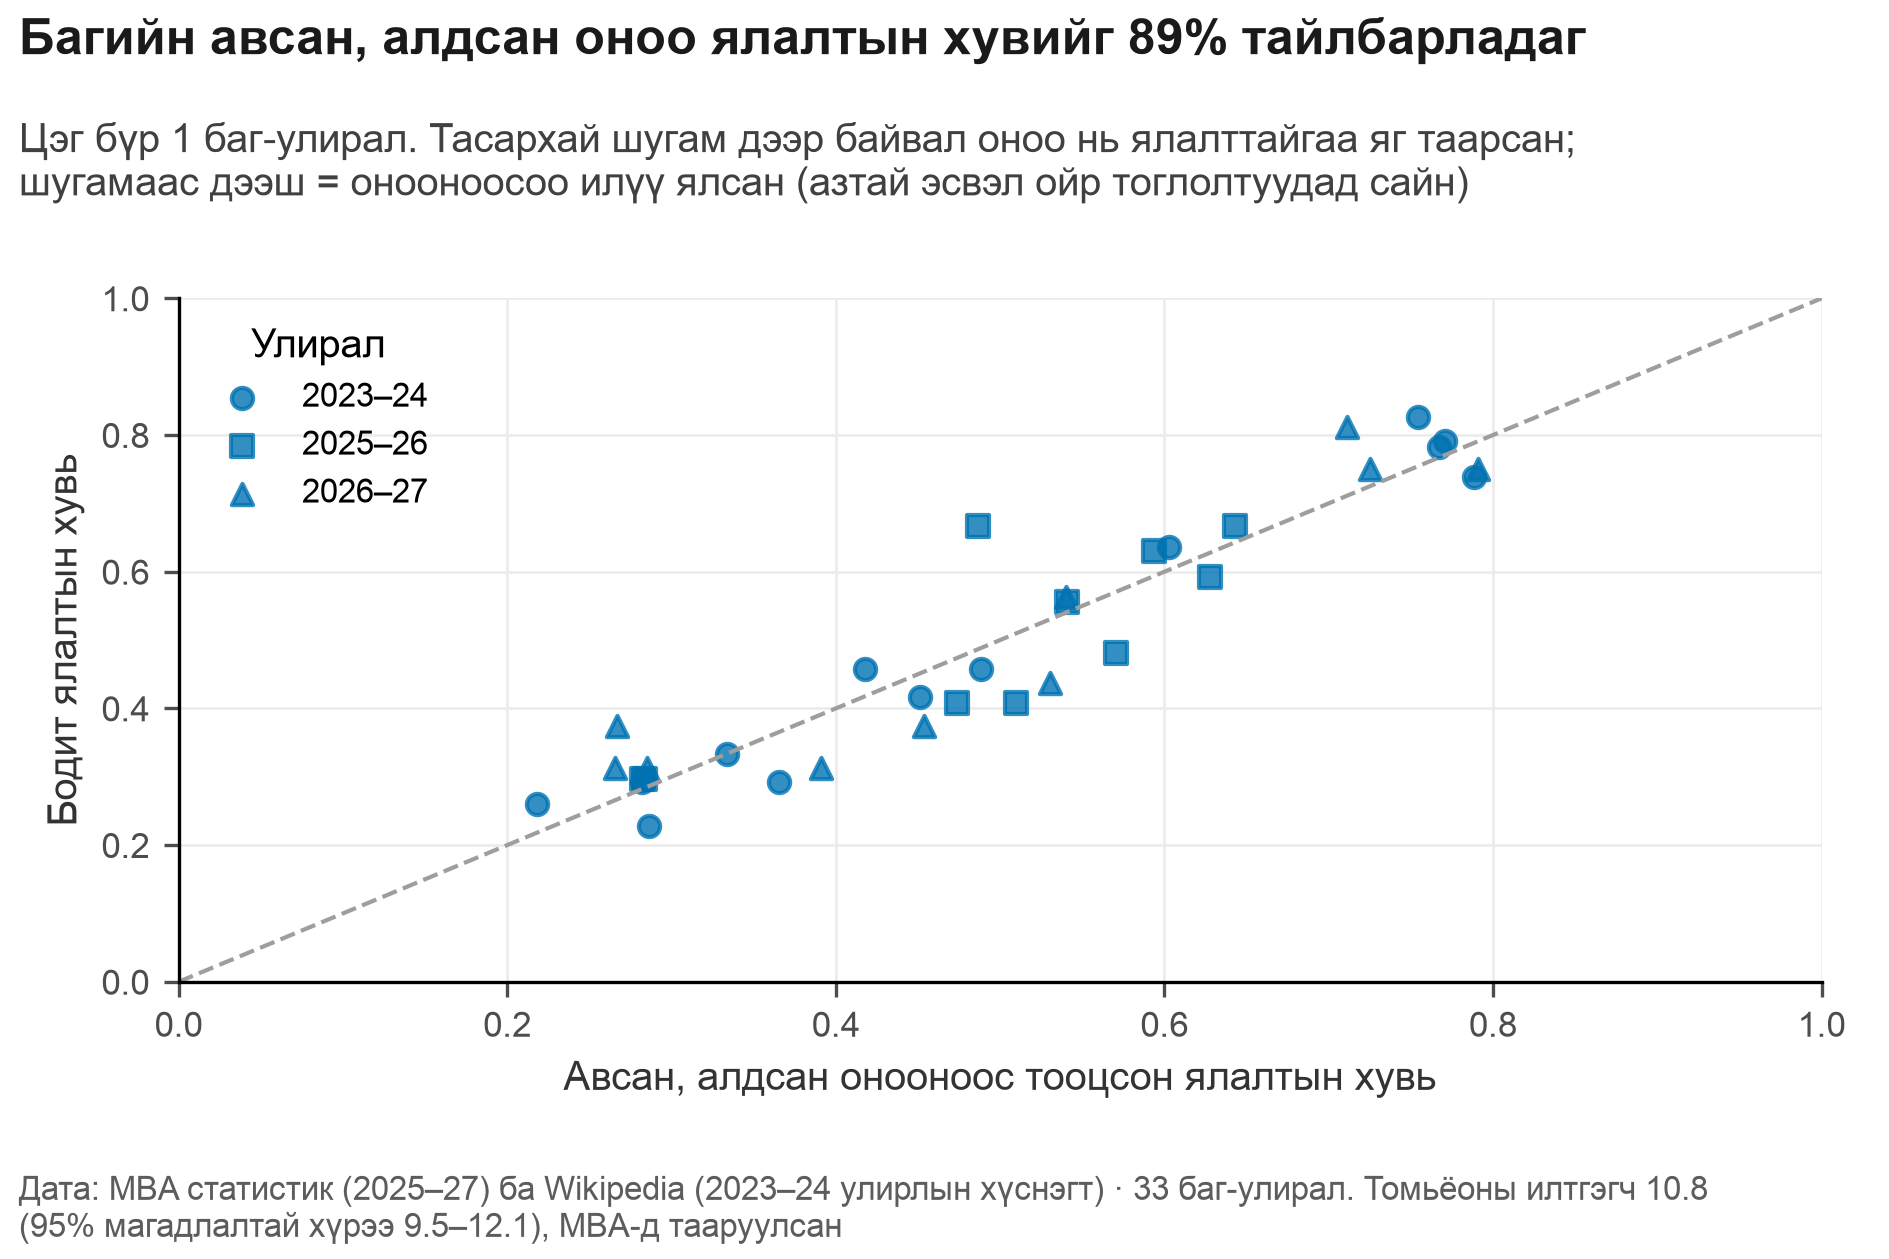

In [19]:
show("F13_pythagorean")